# Tests for `src/mace/loss.py`

Run from the repo root (imports are `src.mace.*`). Each test cell prints `OK` (or `SKIPPED`) or raises an `AssertionError` saying what went wrong.

Restart the kernel after editing `loss.py`, otherwise the old class definition stays in memory.

In [1]:
import math
import os
import shutil
import tempfile
import torch
import torch.nn as nn
from src.mace.loss import (Loss, AbsLoss, GrdLoss, IdnLoss,
                           setup_loss, load_loss, load_old_loss, plot)

torch.manual_seed(0)

W_A, W_B = 1.0, 0.5

def make_loss():
    return Loss({'a': AbsLoss(W_A), 'b': AbsLoss(W_B)})

def make_inputs(shape=(8, 5)):
    n_e = torch.randn(shape)
    n_e_hat = torch.randn(shape, requires_grad=True)
    return n_e, n_e_hat

class DummyModel(nn.Module):
    """Stand-in for Solver: only the encoder/decoder that IdnLoss needs (n_dim=5, p_dim=4, z_dim=3)."""
    def __init__(self, n_dim=5, p_dim=4, z_dim=3):
        super().__init__()
        self.encoder = nn.Linear(p_dim + n_dim, z_dim)
        self.decoder = nn.Linear(z_dim, n_dim)

def trained_loss(nb_epochs=3, calls_per_epoch=2):
    """An abs_idn Loss with a few epochs of history and a non-trivial weight and scale."""
    loss_fn = setup_loss('abs_idn', [1.0, 0.5])
    model = DummyModel()
    for _ in range(nb_epochs):
        for _ in range(calls_per_epoch):
            n, p = torch.rand(6, 5), torch.rand(6, 4)
            loss_fn(n_e=n, n_e_hat=torch.rand(6, 5), n=n, p=p, model=model)
        loss_fn.endEpoch()
    loss_fn.terms['abs'].setScale(2.0)
    return loss_fn, model

## 1. Output format and total
`total` and every part should be a scalar, the parts should be the raw (unweighted) losses, and `total` should equal Σ weight · scale · part.

In [2]:
loss_fn = make_loss()
n_e, n_e_hat = make_inputs()
total, parts = loss_fn(n_e=n_e, n_e_hat=n_e_hat)

expected_raw = ((n_e - n_e_hat)**2).mean()

assert total.dim() == 0, f'total should be a scalar, got shape {tuple(total.shape)}'
assert set(parts) == {'a', 'b'}, f'unexpected part names: {set(parts)}'
for name, value in parts.items():
    assert value.dim() == 0, f'part {name!r} should be a scalar, got shape {tuple(value.shape)}'
    assert torch.allclose(value, expected_raw), f'part {name!r} is not the raw (unweighted) loss'
assert torch.allclose(total, (W_A + W_B) * expected_raw), 'total != sum of weight * scale * part'

print('OK  total =', total.item(), ' parts =', {k: v.item() for k, v in parts.items()})

OK  total = 3.1548409461975098  parts = {'a': 2.103227376937866, 'b': 2.103227376937866}


## 2. Gradients
`backward()` should work, and the gradient should match the analytic one: (w_a + w_b) · 2(ň − n) / N.

In [3]:
loss_fn = make_loss()
n_e, n_e_hat = make_inputs()
total, _ = loss_fn(n_e=n_e, n_e_hat=n_e_hat)
total.backward()

expected_grad = (W_A + W_B) * 2 * (n_e_hat.detach() - n_e) / n_e.numel()

assert n_e_hat.grad is not None, 'no gradient reached the prediction'
assert torch.allclose(n_e_hat.grad, expected_grad), 'gradient does not match the analytic gradient'
print('OK')

OK


## 3. Scale
Changing a term's scale with `setScale()` should change `total`, but not the raw parts.

In [4]:
loss_fn = make_loss()
n_e, n_e_hat = make_inputs()
_, parts_before = loss_fn(n_e=n_e, n_e_hat=n_e_hat)

loss_fn.terms['b'].setScale(4.0)
total_after, parts_after = loss_fn(n_e=n_e, n_e_hat=n_e_hat)

raw = parts_before['a']
assert loss_fn.terms['b'].scale == 4.0, 'setScale() did not set scale'
assert torch.allclose(total_after, (W_A + W_B * 4.0) * raw), 'scale is not applied correctly'
for name in parts_before:
    assert torch.allclose(parts_before[name], parts_after[name]), f'scale changed the raw part {name!r}'
print('OK')

OK


## 4. History per epoch
Calls within an epoch are only accumulated; `endEpoch()` stores one value per term (the mean over the calls) plus `tot` (the mean weighted total), as plain floats, and resets the accumulators.

In [5]:
loss_fn = make_loss()
raw, tot = [], []
for _ in range(3):
    n_e, n_e_hat = make_inputs()
    total, parts = loss_fn(n_e=n_e, n_e_hat=n_e_hat)
    raw.append(parts['a'].item())
    tot.append(total.item())

assert loss_fn.getHistory() == {'a': [], 'b': [], 'tot': []}, 'history should only fill at endEpoch()'
loss_fn.endEpoch()

history = loss_fn.getHistory()
assert set(history) == {'a', 'b', 'tot'}, f'unexpected history keys: {set(history)}'
for name, values in history.items():
    assert len(values) == 1, f'{name!r}: expected 1 entry after 1 epoch, got {len(values)}'
    assert isinstance(values[0], float), f'{name!r}: history should hold floats, not {type(values[0]).__name__}'
for name in ('a', 'b'):
    assert math.isclose(history[name][0], sum(raw) / 3, rel_tol=1e-5), f'{name!r}: epoch value is not the mean over calls'
assert math.isclose(history['tot'][0], sum(tot) / 3, rel_tol=1e-5), 'tot: epoch value is not the mean weighted total'
assert loss_fn._count == 0 and all(t._count == 0 for t in loss_fn.terms.values()), 'accumulators not reset'
print('OK ', history)

OK  {'tot': [4.017588933308919], 'a': [2.6783927281697593], 'b': [2.6783927281697593]}


### 4b. Validation is recorded too, and `endEpoch()` needs at least one call
History is recorded regardless of `train()`/`eval()` mode, so a validation `Loss` under `torch.no_grad()` still fills its history.

In [6]:
loss_fn = make_loss()
loss_fn.eval()
with torch.no_grad():
    loss_fn(n_e=torch.randn(8, 5), n_e_hat=torch.randn(8, 5))
loss_fn.endEpoch()
assert len(loss_fn.getTotHistory()) == 1, 'validation (eval mode) losses were not recorded'

try:
    loss_fn.endEpoch()
except RuntimeError as e:
    print('OK  empty epoch raises:', e)
else:
    raise AssertionError('endEpoch() without any loss calls should raise a RuntimeError')

OK  empty epoch raises: endEpoch() called prematurely.


### 4c. Several epochs and history slicing
`getHistory`, `getTermHistory` and `getTotHistory` accept `start`/`stop` like list slicing.

In [7]:
loss_fn = make_loss()
for epoch in range(5):
    ## (0 - sqrt(10^epoch))^2 = 10^epoch, so every epoch has a known, distinct value
    loss_fn(n_e=torch.zeros(4, 3), n_e_hat=torch.full((4, 3), math.sqrt(10.0 ** epoch)))
    loss_fn.endEpoch()

full = loss_fn.getHistory()
assert all(len(v) == 5 for v in full.values()), 'expected 5 epochs per key'
assert all(math.isclose(x, 10.0 ** i, rel_tol=1e-5) for i, x in enumerate(full['a'])), f'wrong per-epoch values: {full["a"]}'

last2 = loss_fn.getHistory(start=-2)
assert all(last2[k] == full[k][-2:] for k in full), 'getHistory(start=-2) is not the last two epochs'
assert loss_fn.getTotHistory(1, 3) == full['tot'][1:3], 'getTotHistory(1, 3) is not epochs 1-2'
assert set(loss_fn.getTermHistory()) == {'a', 'b'}, 'getTermHistory() should not contain tot'
print('OK')

OK


## 5. Inputs
Extra keyword arguments should be ignored; a missing required one should raise a `TypeError`.

In [8]:
loss_fn = make_loss()
n_e, n_e_hat = make_inputs()

total, _ = loss_fn(n_e=n_e, n_e_hat=n_e_hat, model=None, unused=123)
assert total.dim() == 0

try:
    loss_fn(n_e=n_e)
except TypeError as e:
    print('OK  missing input raises:', e)
else:
    raise AssertionError('a missing n_e_hat should raise a TypeError')

OK  missing input raises: AbsLoss.compute() missing 1 required positional argument: 'n_e_hat'


## 6. `normalise()` (skipped if not implemented yet)
With fake histories of 100 and 1, both terms should have the same magnitude after normalising (scale × mean).

In [9]:
loss_fn = make_loss()

if not hasattr(loss_fn, 'normalize'):
    print('SKIPPED  Loss has no normalise() yet')
else:
    loss_fn.terms['a'].history = [100.0] * 10
    loss_fn.terms['b'].history = [1.0] * 10
    loss_fn.normalize()

    magnitude_a = float(loss_fn.terms['a'].scale) * 100.0
    magnitude_b = float(loss_fn.terms['b'].scale) * 1.0
    assert math.isclose(magnitude_a, magnitude_b, rel_tol=1e-6), \
        f'terms not equalised: {magnitude_a} vs {magnitude_b}'
    print('OK  scales =', {n: float(t.scale) for n, t in loss_fn.terms.items()})

OK  scales = {'a': 0.505, 'b': 50.5}


## 7. `setup_loss()`
Builds the terms from a `losstype` string in order, with weights defaulting to 1, and rejects bad input.

In [10]:
loss_fn = setup_loss('abs_grd_idn', [1.0, 2.0, 3.0])
assert list(loss_fn.terms) == ['abs', 'grd', 'idn'], f'wrong term order: {list(loss_fn.terms)}'
for name, cls in [('abs', AbsLoss), ('grd', GrdLoss), ('idn', IdnLoss)]:
    assert type(loss_fn.terms[name]) is cls, f'{name!r} should be a {cls.__name__}'
assert [t.weight for t in loss_fn.terms.values()] == [1.0, 2.0, 3.0], 'weights not assigned in order'
assert all(t.weight == 1 for t in setup_loss('abs_idn').terms.values()), 'default weights should be 1'

for args in [('abs_idn', [1.0]), ('abs_elm', None)]:
    try:
        setup_loss(*args)
    except RuntimeError as e:
        print('OK  rejects', args, '->', e)
    else:
        raise AssertionError(f'setup_loss{args} should raise a RuntimeError')

OK  rejects ('abs_idn', [1.0]) -> 1 weights for 2 lossterms.
OK  rejects ('abs_elm', None) -> Unrecognized loss type: elm


## 8. `IdnLoss`
Compares `n` with `D(E(cat(p, n)))` (the decoder output has the size of `n`, not of `cat(p, n)`), and passes gradients to the autoencoder.

In [11]:
model = DummyModel()
n, p = torch.rand(6, 5), torch.rand(6, 4)
value = IdnLoss()(n=n, p=p, model=model)

expected = ((n - model.decoder(model.encoder(torch.cat((p, n), dim=-1))))**2).mean()
assert value.dim() == 0, 'IdnLoss should return a scalar'
assert torch.allclose(value, expected), 'IdnLoss does not match (n - D(E(cat(p, n))))^2'
value.backward()
assert model.encoder.weight.grad is not None and model.decoder.weight.grad is not None, 'no gradient reached the autoencoder'
print('OK  idn =', value.item())

OK  idn = 0.519919753074646


## 9. `save()` / `load()` round trip
`save()` creates the folder and writes one `.npy` per term plus `tot.npy`, `weight.json` and `scale.json`. `load()` restores history, weights and scales, and the loaded histories are lists, so training can continue.

In [12]:
tmp = tempfile.mkdtemp()
path = os.path.join(tmp, 'train')            ## does not exist yet: save() should create it

original, model = trained_loss()
original.save(path)
files = set(os.listdir(path))
assert files == {'abs.npy', 'idn.npy', 'tot.npy', 'weight.json', 'scale.json'}, f'unexpected files: {files}'

restored = setup_loss('abs_idn')             ## default weights 1, scales 1
restored.load(path)
assert restored.getHistory() == original.getHistory(), 'history not restored'
for name in original.terms:
    assert restored.terms[name].weight == original.terms[name].weight, f'{name!r}: weight not restored'
    assert restored.terms[name].scale  == original.terms[name].scale,  f'{name!r}: scale not restored'
assert all(type(v) is list for v in restored.getHistory().values()), 'loaded histories should be lists'

n, p = torch.rand(6, 5), torch.rand(6, 4)
restored(n_e=n, n_e_hat=torch.rand(6, 5), n=n, p=p, model=model)
restored.endEpoch()
assert len(restored.getTotHistory()) == 4, 'could not continue training after load()'
print('OK  saved to', path)

Loaded losses for dict_keys(['tot', 'abs', 'idn'])
OK  saved to C:\Users\bartd\AppData\Local\Temp\tmpe6zfl3zu\train


## 10. `load_loss()`
Without `types`, the terms (and their order) are read from `weight.json`.

In [13]:
loaded = load_loss(path)
assert list(loaded.terms) == list(original.terms), f'wrong terms: {list(loaded.terms)}'
assert loaded.getHistory() == original.getHistory(), 'history not restored'
assert {n: t.weight for n, t in loaded.terms.items()} == {'abs': 1.0, 'idn': 0.5}, 'weights not restored'
assert loaded.terms['abs'].scale == 2.0, 'scale not restored'
print('OK')

Loaded losses for dict_keys(['tot', 'abs', 'idn'])
OK


## 11. Loading errors
A missing folder, or a folder without `weight.json`/`scale.json` (old format), raises `FileNotFoundError`; `loadHistory()` alone still works there.

In [14]:
try:
    setup_loss('abs_idn').load(os.path.join(tmp, 'does_not_exist'))
except FileNotFoundError as e:
    print('OK  missing folder raises:', e)
else:
    raise AssertionError('load() from a missing folder should raise FileNotFoundError')

old_style = os.path.join(tmp, 'old_style')
os.makedirs(old_style)
for f in ('abs.npy', 'idn.npy', 'tot.npy'):
    shutil.copy(os.path.join(path, f), old_style)

try:
    setup_loss('abs_idn').load(old_style)
except FileNotFoundError as e:
    print('OK  missing weight.json raises:', e)
else:
    raise AssertionError('load() without weight.json should raise FileNotFoundError')

history_only = setup_loss('abs_idn')
history_only.loadHistory(old_style)
assert history_only.getHistory() == original.getHistory(), 'loadHistory() failed on an old-style folder'
print('OK  loadHistory() works without the .json files')

OK  missing folder raises: Invalid path at C:\Users\bartd\AppData\Local\Temp\tmpe6zfl3zu\does_not_exist
Loaded losses for dict_keys(['tot', 'abs', 'idn'])
OK  missing weight.json raises: Missing weight.json in C:\Users\bartd\AppData\Local\Temp\tmpe6zfl3zu\old_style. Load old models using Loss.loadHistory().
Loaded losses for dict_keys(['tot', 'abs', 'idn'])
OK  loadHistory() works without the .json files


## 12. `load_old_loss()` (skipped if the shipped model is not present)
Reads the histories saved by the old `Loss` class; weights and scales stay 1.

In [15]:
old_path = 'model/20240604_160152/train'
if not os.path.exists(os.path.join(old_path, 'tot.npy')):
    print('SKIPPED  no old-format losses at', old_path)
else:
    old = load_old_loss(old_path)
    lengths = {k: len(v) for k, v in old.getHistory().items()}
    assert set(lengths) == {'abs', 'idn', 'tot'}, f'unexpected keys: {set(lengths)}'
    assert len(set(lengths.values())) == 1, f'histories have different lengths: {lengths}'
    assert all(t.weight == 1 and t.scale == 1 for t in old.terms.values()), 'weights/scales should be 1'
    print('OK ', lengths)

Loaded losses for dict_keys(['tot', 'abs', 'idn'])
OK  {'tot': 150, 'abs': 150, 'idn': 150}


## 13. `plot()`
Takes a dict of `Loss` objects: one line per dataset and key, the same colour for a key across datasets, and every dataset and key once in the legend.

OK


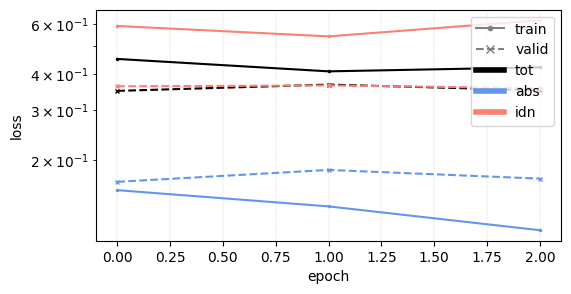

In [16]:
train, _ = trained_loss()
valid, _ = trained_loss()
ax = plot({'train': train, 'valid': valid})

keys = list(train.getHistory())              ## ['abs', 'idn', 'tot']
labels = [t.get_text() for t in ax.get_legend().get_texts()]
assert labels == ['train', 'valid'] + keys, f'unexpected legend: {labels}'
assert len(ax.lines) == 2 * len(keys), f'expected {2 * len(keys)} lines, got {len(ax.lines)}'
for i, key in enumerate(keys):
    assert ax.lines[i].get_color() == ax.lines[i + len(keys)].get_color(), f'{key!r} has different colours in train and valid'
    assert ax.lines[i].get_linestyle() != ax.lines[i + len(keys)].get_linestyle(), 'train and valid share a line style'
print('OK')

In [17]:
shutil.rmtree(tmp)                           ## clean up the temporary save folder